# CA3 Capstone Project 
Dataset: Food Waste Recycling Impact - Town of Cary
https://data.townofcary.org/explore/dataset/food-waste-pilot/

In [59]:
# I used this code to import the libraries I need for data analysis and charts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [60]:
# I used this code to load the dataset and see the first 5 rows
df = pd.read_csv('food-waste-pilot.csv')
df.head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2026-04-29,515.8,52.0
1,Mills Park,2026-04-29,537.0,54.0
2,Mills Park,2026-04-27,561.0,56.0
3,Citizen's Convenience Center,2026-04-27,1093.0,109.0
4,Citizen's Convenience Center,2026-04-24,641.6,64.0


In [61]:
# I used this code to check the size of the dataset (rows, columns)
df.shape

(1006, 4)

i saw, the dataset has 1006 rows and 4 columns.

In [62]:
# I used this code to check the data type of each column and see if there are empty values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1006 entries, 0 to 1005
Data columns (total 4 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Stop Name                         1006 non-null   str    
 1   Collection Date                   1006 non-null   str    
 2   Food Waste Collected              1006 non-null   float64
 3   Estimated Earned Compost Created  1006 non-null   float64
dtypes: float64(2), str(2)
memory usage: 62.7 KB


In [63]:
# I used this code to see the main statistics of the numeric columns
df.describe()

,Food Waste Collected,Estimated Earned Compost Created
count,1006.000000,1006.000000
mean,644.130219,64.382704
std,307.244105,30.726067
min,0.000000,0.000000
25%,452.900000,45.000000
50%,598.400000,60.000000
75%,762.975000,76.000000
max,2057.000000,206.000000


i can see, the average food waste per collection is about 644 lbs. The minimum is 0 lbs, which may mean the site was closed that day, and the maximum is about 2,057 lbs, which may be an outlier.

In [64]:
# I used this code to see how many collections each drop-off site has
df['Stop Name'].value_counts()

Stop Name
Citizen's Convenience Center    656
Mills Park                      350
Name: count, dtype: int64

As we can see, there are 2 sites: Citizen's Convenience Center (656 collections) and Mills Park (350 collections). Our target is Food Waste Collected.

In [65]:
# I used this code to check if there are missing values in each column
df.isnull().sum()

Stop Name                           0
Collection Date                     0
Food Waste Collected                0
Estimated Earned Compost Created    0
dtype: int64

So, there are no missing values in the dataset.

In [66]:
# I used this code to convert the Collection Date from text to a real date,
# so I can sort the data by time and create date features later
df['Collection Date'] = pd.to_datetime(df['Collection Date'])
df['Collection Date'].min(), df['Collection Date'].max()

(Timestamp('2022-02-02 00:00:00'), Timestamp('2026-04-29 00:00:00'))

i saw, the data covers more than 4 years, from February 2022 to April 2026.

In [67]:
# I used this code to find duplicated collections
df[df.duplicated(['Stop Name', 'Collection Date'], keep=False)]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
463,Citizen's Convenience Center,2024-11-01,867.0,87.0
464,Citizen's Convenience Center,2024-11-01,481.8,48.0


In [68]:
# I used this code to add the two pickups together, so each site has only one row per day
df = df.groupby(['Stop Name', 'Collection Date'], as_index=False)[['Food Waste Collected', 'Estimated Earned Compost Created']].sum()
df.shape

(1005, 4)

i see, the dataset now has 1005 rows.

In [69]:
# I used this code to find the collections with 0 lbs of food waste
df[df['Food Waste Collected'] == 0]

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
0,Citizen's Convenience Center,2022-02-02,0.0,0.0
90,Citizen's Convenience Center,2022-09-05,0.0,0.0
119,Citizen's Convenience Center,2022-11-11,0.0,0.0
147,Citizen's Convenience Center,2023-01-16,0.0,0.0
209,Citizen's Convenience Center,2023-06-19,0.0,0.0
298,Citizen's Convenience Center,2024-01-15,0.0,0.0
364,Citizen's Convenience Center,2024-06-19,0.0,0.0
456,Citizen's Convenience Center,2025-01-20,0.0,0.0
457,Citizen's Convenience Center,2025-01-22,0.0,0.0
493,Citizen's Convenience Center,2025-04-17,0.0,0.0


from this table i see, there are 15 collections with 0 lbs. These dates are public holidays In the USA (for example Labor Day and Juneteenth), so the site was closed. A 0 here does not mean "no food waste", so I will remove these rows.

In [70]:
# I used this code to remove the days when the site was closed
df = df[df['Food Waste Collected'] > 0]
df.shape

(990, 4)

In [71]:
# I used this code to check the first collections at Mills Park
df[df['Stop Name'] == 'Mills Park'].sort_values('Collection Date').head()

,Stop Name,Collection Date,Food Waste Collected,Estimated Earned Compost Created
655,Mills Park,2022-08-25,664.8,66.0
657,Mills Park,2024-02-02,66.4,7.0
658,Mills Park,2024-02-05,171.8,17.0
659,Mills Park,2024-02-07,207.0,21.0
660,Mills Park,2024-02-09,181.4,18.0


i saw there is one Mills Park collection in August 2022, and then nothing Until January 2024. Mills Park opened in 2024, so this row is probably a data entry error.

In [72]:
# I used this code to remove the wrong Mills Park row from 2022
df = df[~((df['Stop Name'] == 'Mills Park') & (df['Collection Date'] < '2024-01-01'))]
df.shape

(989, 4)

In [73]:
# I used this code to check the correlation between the food waste and the compost created
df[['Food Waste Collected', 'Estimated Earned Compost Created']].corr()

,Food Waste Collected,Estimated Earned Compost Created
Food Waste Collected,1.000000,0.999952
Estimated Earned Compost Created,0.999952,1.000000


In [74]:
# I used this code to remove the compost column to avoid data leakage
df = df.drop('Estimated Earned Compost Created', axis=1)
df.head()

,Stop Name,Collection Date,Food Waste Collected
1,Citizen's Convenience Center,2022-02-09,59.0
2,Citizen's Convenience Center,2022-02-11,197.0
3,Citizen's Convenience Center,2022-02-14,329.4
4,Citizen's Convenience Center,2022-02-16,102.8
5,Citizen's Convenience Center,2022-02-18,202.8


i see, the dataset now has only 3 columns: Stop Name, Collection Date and Food Waste Collected.

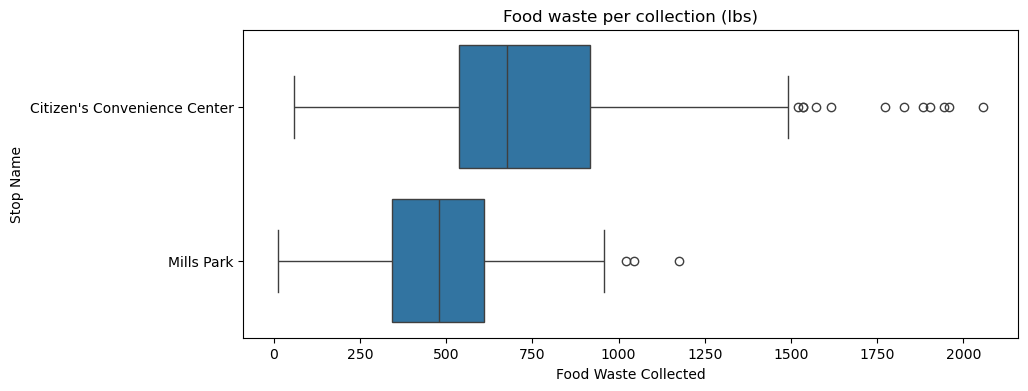

In [75]:
# I used this code to look for outliers in the food waste for each site
plt.figure(figsize=(10, 4))
sns.boxplot(x='Food Waste Collected', y='Stop Name', data=df)
plt.title('Food waste per collection (lbs)')
plt.show()

In [76]:
# I used this code to count the outliers with the IQR method and see on which days they happen
Q1 = df['Food Waste Collected'].quantile(0.25)
Q3 = df['Food Waste Collected'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[df['Food Waste Collected'] > Q3 + 1.5 * IQR]
print('Number of outliers:', len(outliers))
outliers['Collection Date'].dt.day_name().value_counts()

Number of outliers: 55


Collection Date
Monday       44
Wednesday     5
Tuesday       3
Friday        3
Name: count, dtype: int64

i can see, there are 55 outliers and 44 of them are on Mondays. On Monday, the site collects the food waste of the whole weekend, so the amount is bigger. These values are real, no errors, so I will keep them.

#### Exploratory Data Analysis (EDA)

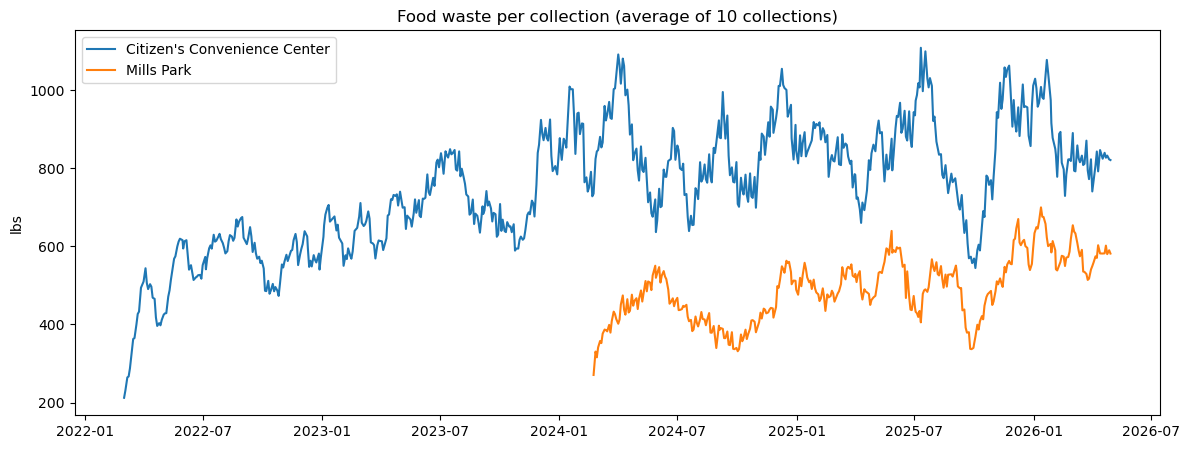

In [77]:
# I used this code to see how the food waste changes over time at each site.
# I used a rolling average of 10 collections to make the trend easier to see.
plt.figure(figsize=(14, 5))
for site in df['Stop Name'].unique():
    s = df[df['Stop Name'] == site].set_index('Collection Date')['Food Waste Collected']
    plt.plot(s.rolling(10).mean(), label=site)
plt.title('Food waste per collection (average of 10 collections)')
plt.ylabel('lbs')
plt.legend()
plt.show()

i saw, Citizen's Convenience Center has been collecting food waste since 2022, and Mills Park only since 2024. The amount per collection goes up and down, but there is a general increase over time.

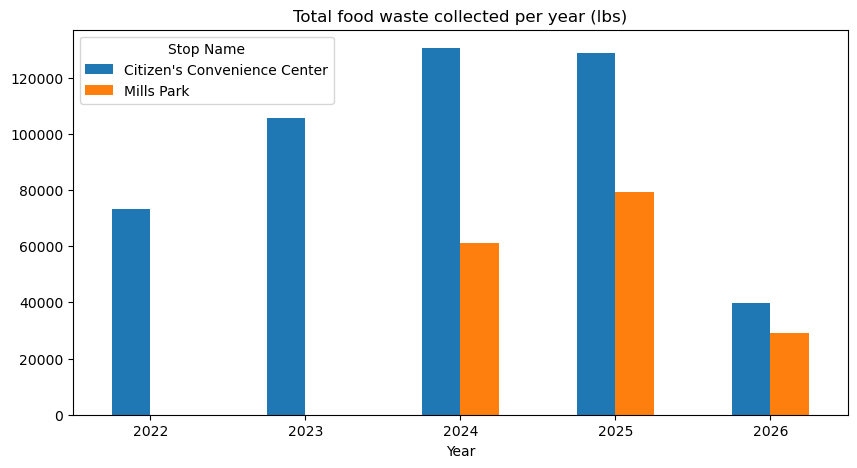

In [78]:
# I used this code to compare the total food waste collected each year at each site
df.groupby([df['Collection Date'].dt.year, 'Stop Name'])['Food Waste Collected'].sum().unstack().plot.bar(figsize=(10, 5))
plt.title('Total food waste collected per year (lbs)')
plt.xlabel('Year')
plt.xticks(rotation=0)
plt.show()

from this chart i see, the food waste collected at Citizen's Convenience Center increased from about 73,000 lbs in 2022 to about 130,000 lbs in 2024. Mills Park also increased, From about 61,000 lbs in 2024 to about 79,000 lbs in 2025. This shows that more and more residents use the service. 2026 is lower because the data stops in April.

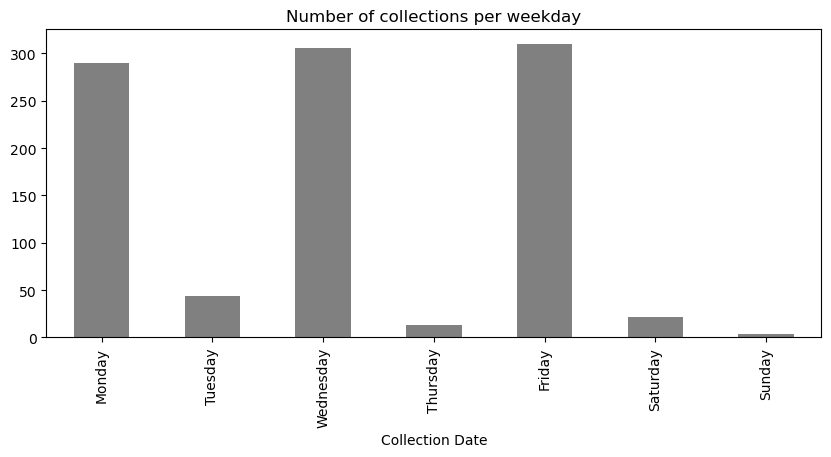

In [79]:
# I used this code to see on which days of the week the collections happen
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['Collection Date'].dt.day_name().value_counts().reindex(order).plot.bar(figsize=(10, 4), color='grey')
plt.title('Number of collections per weekday')
plt.show()

most collections happen on Monday, Wednesday and Friday (about 300 each). The other days are rare.

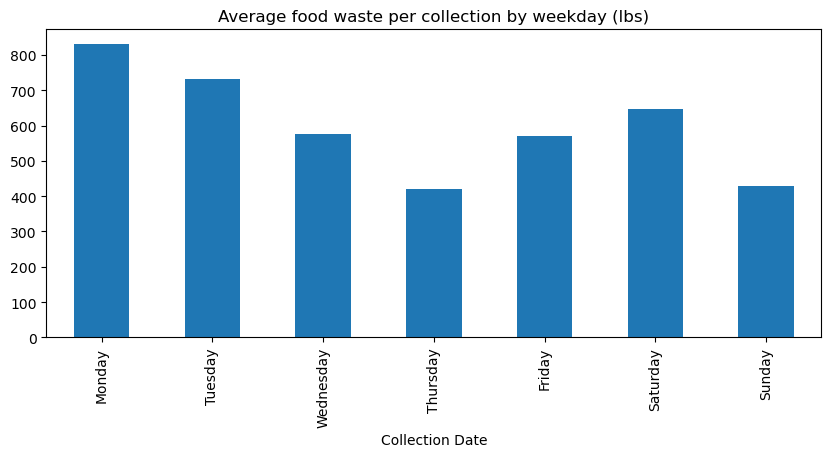

In [80]:
# I used this code to compare the average food waste for each day of the week
df.groupby(df['Collection Date'].dt.day_name())['Food Waste Collected'].mean().reindex(order).plot.bar(figsize=(10, 4))
plt.title('Average food waste per collection by weekday (lbs)')
plt.show()

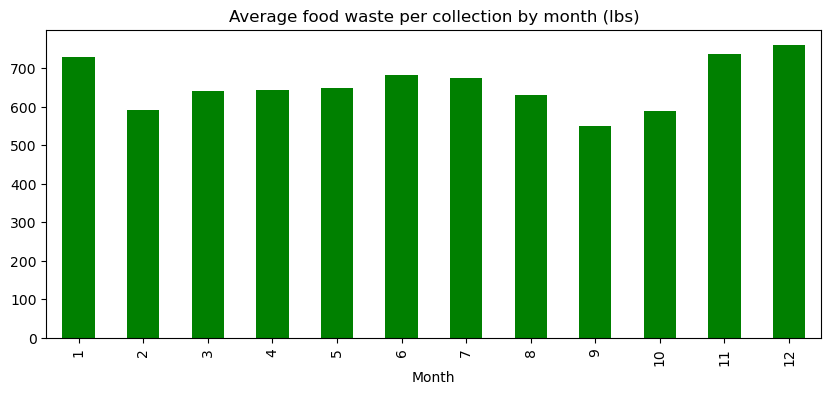

In [81]:
# I used this code to see if the food waste changes with the month of the year (seasonality)
df.groupby(df['Collection Date'].dt.month)['Food Waste Collected'].mean().plot.bar(figsize=(10, 4), color='green')
plt.title('Average food waste per collection by month (lbs)')
plt.xlabel('Month')
plt.show()

i see, November, December and January have the highest food waste (about 730-760 lbs per collection), probably because of the holidays (Thanksgiving, Christmas). September and October are the lowest.

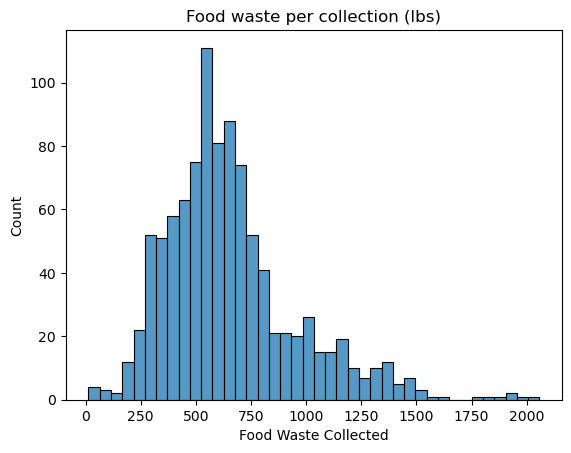

In [82]:
# I used this code to see the distribution of the target (Food Waste Collected)
sns.histplot(df['Food Waste Collected'], bins=40)
plt.title('Food waste per collection (lbs)')
plt.show()

i can see, most collections are between about 460 and 770 lbs. The distribution is right-skewed: a few collections are much bigger (up to about 2,057 lbs), mostly on Mondays.

#### Feature Engineering

In [83]:
# I used this code to sort the data by site and by date,
# because the lag features need the collections in the right time order
df = df.sort_values(['Stop Name', 'Collection Date']).reset_index(drop=True)
g = df.groupby('Stop Name')

In [84]:
# I used this code to create calendar features from the date,
# because the EDA showed that the weekday and the month change the food waste
df['day_of_week'] = df['Collection Date'].dt.dayofweek   # 0 = Monday
df['month'] = df['Collection Date'].dt.month
df['year'] = df['Collection Date'].dt.year
df['is_monday'] = np.where(df['day_of_week'] == 0, 1, 0)
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0


In [85]:
# I used this code to calculate the number of days since the previous collection at the same site,
# because more days (weekend, holidays) means more food waste.
# I also calculated how long the site has been open, because the service grows over time.
df['days_since_last'] = g['Collection Date'].diff().dt.days
df['site_age_days'] = (df['Collection Date'] - g['Collection Date'].transform('min')).dt.days
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9


In [86]:
# I used this code to create lag features: the food waste of the previous collections.
# shift() only takes values from the past, so there is no data leakage.
df['lag_1'] = g['Food Waste Collected'].shift(1)   # previous collection
df['lag_2'] = g['Food Waste Collected'].shift(2)   # 2 collections before
df['lag_3'] = g['Food Waste Collected'].shift(3)   # about the same weekday last week
df.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0,NaN,NaN,NaN
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2,59.0,NaN,NaN
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5,197.0,59.0,NaN
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7,329.4,197.0,59.0
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9,102.8,329.4,197.0


In [87]:
# I used this code to calculate the average of the past collections (rolling averages),
# to give the model the recent level of food waste.
# I used shift(1) first, so the current collection is NOT included (no data leakage).
df['rolling_mean_3'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(3).mean())
df['rolling_mean_6'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(6).mean())
df['rolling_mean_12'] = g['Food Waste Collected'].transform(lambda s: s.shift(1).rolling(12).mean())
df.head(15)

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12
0,Citizen's Convenience Center,2022-02-09,59.0,2,2,2022,0,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,Citizen's Convenience Center,2022-02-11,197.0,4,2,2022,0,2.0,2,59.0,NaN,NaN,NaN,NaN,NaN
2,Citizen's Convenience Center,2022-02-14,329.4,0,2,2022,1,3.0,5,197.0,59.0,NaN,NaN,NaN,NaN
3,Citizen's Convenience Center,2022-02-16,102.8,2,2,2022,0,2.0,7,329.4,197.0,59.0,195.133333,NaN,NaN
4,Citizen's Convenience Center,2022-02-18,202.8,4,2,2022,0,2.0,9,102.8,329.4,197.0,209.733333,NaN,NaN
5,Citizen's Convenience Center,2022-02-21,183.8,0,2,2022,1,3.0,12,202.8,102.8,329.4,211.666667,NaN,NaN
6,Citizen's Convenience Center,2022-02-23,283.0,2,2,2022,0,2.0,14,183.8,202.8,102.8,163.133333,179.133333,NaN
7,Citizen's Convenience Center,2022-02-25,250.8,4,2,2022,0,2.0,16,283.0,183.8,202.8,223.200000,216.466667,NaN
8,Citizen's Convenience Center,2022-02-28,213.8,0,2,2022,1,3.0,19,250.8,283.0,183.8,239.200000,225.433333,NaN
9,Citizen's Convenience Center,2022-03-02,298.8,2,3,2022,0,2.0,21,213.8,250.8,283.0,249.200000,206.166667,NaN


In [88]:
# I used this code to remove the first rows of each site that have no history
df = df.dropna().reset_index(drop=True)
df.shape

(965, 15)

In [89]:
# I used this code to change Stop Name (text) into a number (0 or 1),
# because machine learning models only work with numbers
site = pd.get_dummies(df['Stop Name'], drop_first=True, dtype=int)
data = pd.concat([df, site], axis=1)
data.head()

,Stop Name,Collection Date,Food Waste Collected,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12,Mills Park
0,Citizen's Convenience Center,2022-03-09,352.8,2,3,2022,0,2.0,28,531.2,246.8,298.8,358.933333,304.066667,241.600000,0
1,Citizen's Convenience Center,2022-03-11,309.4,4,3,2022,0,2.0,30,352.8,531.2,246.8,376.933333,315.700000,266.083333,0
2,Citizen's Convenience Center,2022-03-14,659.2,0,3,2022,1,3.0,33,309.4,352.8,531.2,397.800000,325.466667,275.450000,0
3,Citizen's Convenience Center,2022-03-16,481.8,2,3,2022,0,2.0,35,659.2,309.4,352.8,440.466667,399.700000,302.933333,0
4,Citizen's Convenience Center,2022-03-18,303.8,4,3,2022,0,2.0,37,481.8,659.2,309.4,483.466667,430.200000,334.516667,0


In [90]:
# I used this code to separate the features (X) from the target (y).
# I removed the text and date columns, and the target itself.
X = data.drop(['Stop Name', 'Collection Date', 'Food Waste Collected'], axis=1)
y = data['Food Waste Collected']
X.head()

,day_of_week,month,year,is_monday,days_since_last,site_age_days,lag_1,lag_2,lag_3,rolling_mean_3,rolling_mean_6,rolling_mean_12,Mills Park
0,2,3,2022,0,2.0,28,531.2,246.8,298.8,358.933333,304.066667,241.600000,0
1,4,3,2022,0,2.0,30,352.8,531.2,246.8,376.933333,315.700000,266.083333,0
2,0,3,2022,1,3.0,33,309.4,352.8,531.2,397.800000,325.466667,275.450000,0
3,2,3,2022,0,2.0,35,659.2,309.4,352.8,440.466667,399.700000,302.933333,0
4,4,3,2022,0,2.0,37,481.8,659.2,309.4,483.466667,430.200000,334.516667,0


In [91]:
# I used this code to split the data by time, not randomly:
# before July 2025 = train, from July 2025 = test.
# A random split would let the model learn from the future, which is not realistic.
train_idx = data['Collection Date'] < '2025-07-01'
test_idx = data['Collection Date'] >= '2025-07-01'

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
X_train.shape, X_test.shape

((710, 13), (255, 13))

i see, the train set has 710 collections and the test set has 255 collections (about 74% / 26%). The test set is the last 10 months (July 2025 - April 2026).

### Feature Selection

In [92]:
# I used this code to find the features that have the same value in every row (zero variance),
# because a constant feature gives no information to the model
from sklearn.feature_selection import VarianceThreshold
var_thres = VarianceThreshold(threshold=0)
var_thres.fit(X_train)

,threshold,0


In [93]:
# I used this code to see which features are kept (True) and which are constant (False)
var_thres.get_support()

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True])

In [94]:
# I used this code to get the names of the constant features
constant_columns = [column for column in X_train.columns
                    if column not in X_train.columns[var_thres.get_support()]]
print(len(constant_columns))
constant_columns

0


[]

#### Correlation

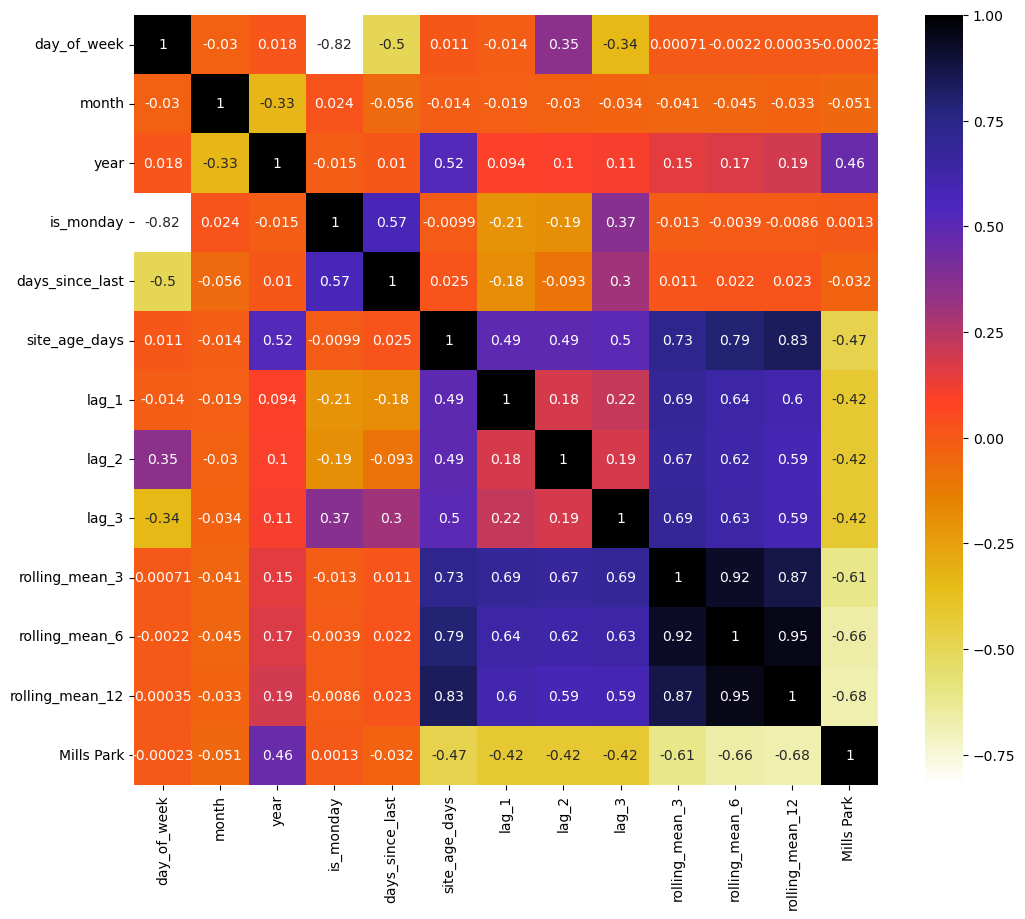

In [95]:
# I used this code to draw a heatmap of the correlation between all the features
plt.figure(figsize=(12, 10))
cor = X_train.corr()
sns.heatmap(cor, annot=True, cmap=plt.cm.CMRmap_r)
plt.show()

In [96]:
# I used this function  to find the features
# that are highly correlated with another feature
def correlation(dataset, threshold):
    col_corr = set()  # Set of all the names of correlated columns
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: # we are interested in absolute coeff value
                colname = corr_matrix.columns[i]  # getting the name of column
                col_corr.add(colname)
    return col_corr

In [97]:
# I used this code to find the features with a correlation above 0.85
corr_features = correlation(X_train, 0.85)
len(set(corr_features)), corr_features

(2, {'rolling_mean_12', 'rolling_mean_6'})

so 2 features are highly correlated: rolling_mean_6 and rolling_mean_12. They give almost the same information as rolling_mean_3, so I will remove them to make the model simpler.

In [98]:
# I used this code to remove the correlated features from the train and the test sets
X_train = X_train.drop(corr_features, axis=1)
X_test = X_test.drop(corr_features, axis=1)
X_train.shape, X_test.shape

((710, 11), (255, 11))

In [99]:
# I used this code to measure how much each feature tells us about the food waste.
# 0 means no link, a higher value means a stronger link.
from sklearn.feature_selection import mutual_info_regression
mutual_info = mutual_info_regression(X_train, y_train, random_state=42)
mutual_info = pd.Series(mutual_info)
mutual_info.index = X_train.columns
mutual_info.sort_values(ascending=False)

lag_3              0.235349
site_age_days      0.193983
rolling_mean_3     0.176606
days_since_last    0.129270
Mills Park         0.127876
day_of_week        0.105417
is_monday          0.081220
year               0.047982
month              0.039020
lag_1              0.023497
lag_2              0.008487
dtype: float64

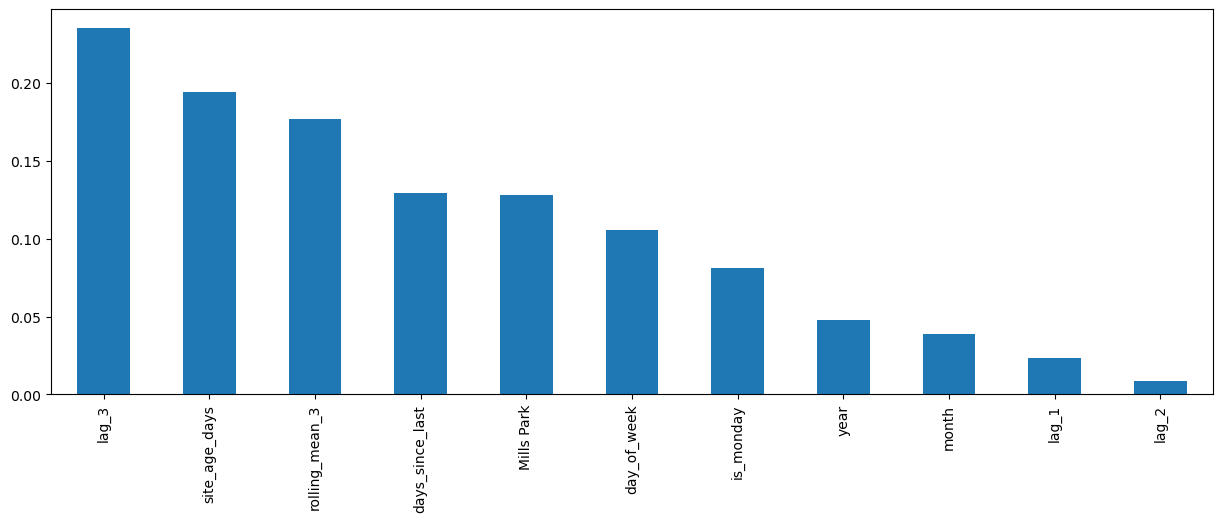

In [100]:
# I used this code to show the mutual information of each feature in a bar chart
mutual_info.sort_values(ascending=False).plot.bar(figsize=(15, 5))
plt.show()

In [101]:
# I used this code to select the top 50% of the features with the highest mutual information
from sklearn.feature_selection import SelectPercentile
selected_top_columns = SelectPercentile(mutual_info_regression, percentile=50)
selected_top_columns.fit(X_train, y_train)
X_train.columns[selected_top_columns.get_support()]

Index(['days_since_last', 'site_age_days', 'lag_3', 'rolling_mean_3',
       'Mills Park'],
      dtype='str')

In [102]:
# I used this code to create a class (0 or 1), because chi-square and mutual information
# for classification need a class target:
# high_waste = 1 if the collection is above the usual level (median) of its site
median_by_site = data.groupby('Stop Name')['Food Waste Collected'].transform('median')
data['high_waste'] = np.where(data['Food Waste Collected'] > median_by_site, 1, 0)
data['high_waste'].value_counts()

high_waste
0    483
1    482
Name: count, dtype: int64

In [103]:
# I used this code to keep only the calendar and site features (they are all positive,
# which is needed for chi-square) and to split them into train and test
from sklearn.model_selection import train_test_split
cat_cols = ['day_of_week', 'is_monday', 'month', 'year', 'Mills Park']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(data[cat_cols], data['high_waste'],
                                                        test_size=0.3, random_state=100)
Xc_train.head()

,day_of_week,is_monday,month,year,Mills Park
404,0,1,11,2024,0
105,0,1,11,2022,0
523,0,1,8,2025,0
851,0,1,8,2025,1
445,2,0,2,2025,0


In [104]:
# I used this code to measure the mutual information between each feature and high_waste
from sklearn.feature_selection import mutual_info_classif
mutual_info_c = mutual_info_classif(Xc_train, yc_train, random_state=42)
mutual_info_c = pd.Series(mutual_info_c, index=Xc_train.columns)
mutual_info_c.sort_values(ascending=False)

day_of_week    0.060308
is_monday      0.044506
year           0.039538
month          0.010495
Mills Park     0.000000
dtype: float64

In [105]:
# I used this code to measure the mutual information between each feature and high_waste
from sklearn.feature_selection import mutual_info_classif
mutual_info_c = mutual_info_classif(Xc_train, yc_train, random_state=42)
mutual_info_c = pd.Series(mutual_info_c, index=Xc_train.columns)
mutual_info_c.sort_values(ascending=False)

day_of_week    0.060308
is_monday      0.044506
year           0.039538
month          0.010495
Mills Park     0.000000
dtype: float64

In [106]:
# I used this code to select the 3 best features for high_waste
from sklearn.feature_selection import SelectKBest
sel_three_cols = SelectKBest(mutual_info_classif, k=3)
sel_three_cols.fit(Xc_train, yc_train)
Xc_train.columns[sel_three_cols.get_support()]

Index(['day_of_week', 'is_monday', 'year'], dtype='str')

In [107]:
# I used this code to run the chi-square test, which gives a score and a p-value for each feature
from sklearn.feature_selection import chi2
f_p_values = chi2(Xc_train, yc_train)
p_values = pd.Series(f_p_values[1])
p_values.index = Xc_train.columns
p_values.sort_values(ascending=True)

day_of_week    3.743705e-19
is_monday      9.918602e-14
month          1.856345e-01
year           8.693240e-01
Mills Park     9.713165e-01
dtype: float64

#### Model Building

In [108]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [109]:
# I used this code to import the models, the tuning tools and the metrics
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [110]:
# I used this code to create a function that calculates the 3 metrics for each model:
# MAE = average error in lbs, RMSE = gives more weight to big errors, R2 = how much of the variation is explained
def evaluate(y_true, y_pred, name):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

In [111]:
# I used this code to sort the train data by date and to prepare the time series cross validation,
# so each model is always trained on the past and validated on the future
order_idx = data.loc[X_train.index, 'Collection Date'].sort_values(kind='stable').index
X_train, y_train = X_train.loc[order_idx], y_train.loc[order_idx]

tscv = TimeSeriesSplit(n_splits=5)
results = []

In [112]:
# I used this code to create a naive baseline: the prediction is the food waste of the same weekday
# last week (lag_3). A good model must be better than this simple rule.
results.append(evaluate(y_test, X_test['lag_3'], 'Naive baseline (same day last week)'))
pd.DataFrame(results)

,Model,MAE,RMSE,R2
0,Naive baseline (same day last week),232.232941,328.934025,-0.104698


In [113]:
# I used this code to train a Ridge regression. I put a StandardScaler in a pipeline
# because linear models need features on the same scale.
# RandomizedSearchCV tests different values of alpha to find the best one.
ridge_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
ridge_params = {'model__alpha': [0.01, 0.1, 1, 10, 50, 100, 500]}

ridge_search = RandomizedSearchCV(ridge_pipe, ridge_params, n_iter=7, cv=tscv,
                                  scoring='neg_mean_absolute_error', random_state=42, n_jobs=-1)
ridge_search.fit(X_train, y_train)
ridge_search.best_params_

{'model__alpha': 10}

In [114]:
# I used this code to keep the best Ridge model and test it on the test set
ridge_best = ridge_search.best_estimator_
results.append(evaluate(y_test, ridge_best.predict(X_test), 'Linear Regression (Ridge)'))

### Random Forest

In [115]:
# I used this code to train a Random Forest and tune its main hyperparameters
# (number of trees, depth of the trees, minimum rows per leaf, number of features per split)
rf_params = {'n_estimators': [100, 200, 300],
             'max_depth': [3, 5, 8, 12, None],
             'min_samples_leaf': [1, 3, 5, 10],
             'max_features': ['sqrt', 0.5, 1.0]}

rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), rf_params,
                               n_iter=15, cv=tscv, scoring='neg_mean_absolute_error',
                               random_state=42, n_jobs=-1)
rf_search.fit(X_train, y_train)
rf_search.best_params_

{'n_estimators': 100,
 'min_samples_leaf': 10,
 'max_features': 0.5,
 'max_depth': 8}

In [116]:
# I used this code to keep the best Random Forest model and test it on the test set
rf_best = rf_search.best_estimator_
results.append(evaluate(y_test, rf_best.predict(X_test), 'Random Forest'))

### XGBoost

In [117]:
# I used this code to train an XGBoost model and tune its main hyperparameters
# (number of trees, learning rate, depth, and the part of rows and features used by each tree)
xgb_params = {'n_estimators': [100, 200, 400],
              'learning_rate': [0.02, 0.05, 0.1],
              'max_depth': [2, 3, 4, 5],
              'subsample': [0.7, 0.85, 1.0],
              'colsample_bytree': [0.6, 0.8, 1.0],
              'min_child_weight': [1, 5, 10]}

xgb_search = RandomizedSearchCV(XGBRegressor(random_state=42, n_jobs=-1), xgb_params,
                                n_iter=20, cv=tscv, scoring='neg_mean_absolute_error',
                                random_state=42, n_jobs=-1)
xgb_search.fit(X_train, y_train)
xgb_search.best_params_

{'subsample': 0.85,
 'n_estimators': 100,
 'min_child_weight': 10,
 'max_depth': 3,
 'learning_rate': 0.05,
 'colsample_bytree': 0.8}

In [118]:
# I used this code to keep the best XGBoost model and test it on the test set
xgb_best = xgb_search.best_estimator_
results.append(evaluate(y_test, xgb_best.predict(X_test), 'XGBoost'))

In [119]:
# I used this code to put the results of all the models in one table
results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

,MAE,RMSE,R2
Model,,,
Naive baseline (same day last week),232.233,328.934,-0.105
Linear Regression (Ridge),194.807,255.453,0.334
Random Forest,181.164,249.986,0.362
XGBoost,197.447,263.872,0.289


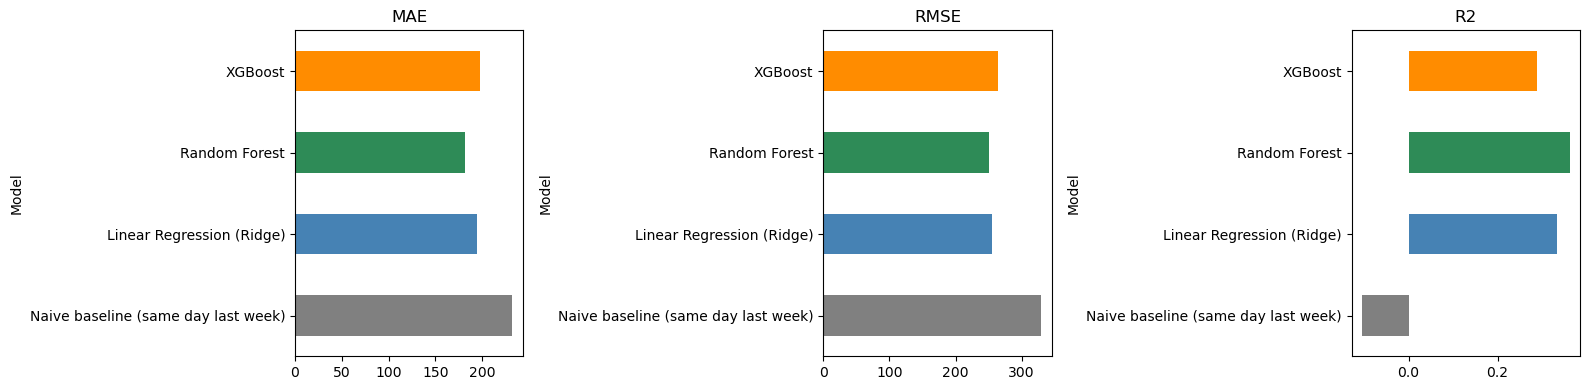

In [120]:
# I used this code to compare the models in charts for each metric
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    results_df[metric].plot.barh(ax=ax, color=['grey', 'steelblue', 'seagreen', 'darkorange'])
    ax.set_title(metric)
plt.tight_layout()
plt.show()

In [121]:
# I used this code to calculate how much better each model is than the naive rule (in %)
base_mae = results_df.loc['Naive baseline (same day last week)', 'MAE']
((base_mae - results_df['MAE']) / base_mae * 100).round(1)

Model
Naive baseline (same day last week)     0.0
Linear Regression (Ridge)              16.1
Random Forest                          22.0
XGBoost                                15.0
Name: MAE, dtype: float64

In [122]:
# I used this code to choose the best model automatically and save it in a file,
# so I can use it later without training it again
best_name = results_df.drop('Naive baseline (same day last week)')['MAE'].idxmin()
best_model = {'Linear Regression (Ridge)': ridge_best, 'Random Forest': rf_best, 'XGBoost': xgb_best}[best_name]
print('Best model:', best_name)

import pickle
pickle.dump(best_model, open('best_model.pkl', 'wb'))

Best model: Random Forest


### Model Validation

I used 2 levels of validation:

TimeSeriesSplit cross validation (5 folds) on the train data.
A hold-out test period (July 2025 - April 2026) that the models never saw during tuning.


In [123]:
# I used this code to run cross validation on the 3 best models,
# to check if their results are stable over different time periods
cv_table = {}
for name, model in [('Ridge', ridge_best), ('Random Forest', rf_best), ('XGBoost', xgb_best)]:
    scores = -cross_val_score(model, X_train, y_train, cv=tscv,
                              scoring='neg_mean_absolute_error', n_jobs=-1)
    cv_table[name] = scores

cv_df = pd.DataFrame(cv_table, index=['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']).round(2)
cv_df.loc['Mean'] = cv_df.mean().round(2)
cv_df.loc['Std'] = cv_df.iloc[:5].std().round(2)
cv_df

,Ridge,Random Forest,XGBoost
Fold 1,158.17,176.68,184.87
Fold 2,199.95,187.54,191.95
Fold 3,160.84,156.79,166.29
Fold 4,159.03,147.12,152.09
Fold 5,176.41,177.10,176.62
Mean,170.88,169.05,174.36
Std,17.88,16.55,15.70


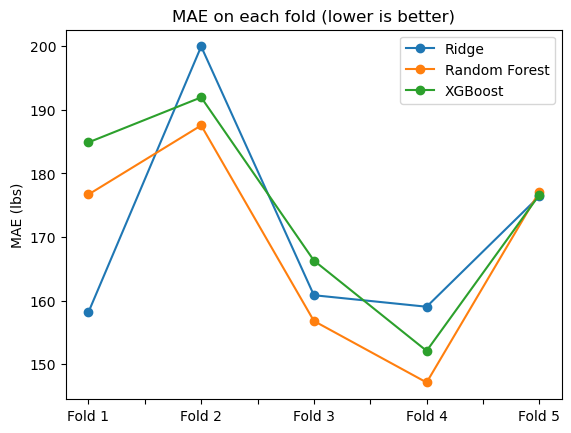

In [124]:
# I used this code to show the error of each model on each fold in a chart
cv_df.iloc[:5].plot(marker='o')
plt.title('MAE on each fold (lower is better)')
plt.ylabel('MAE (lbs)')
plt.show()

i saw the 3 models follow the same pattern on each fold, and none of them has a very bad fold. The test MAE of Random Forest (181 lbs) is close to its cross validation MAE (169 lbs), so there is no big overfitting.



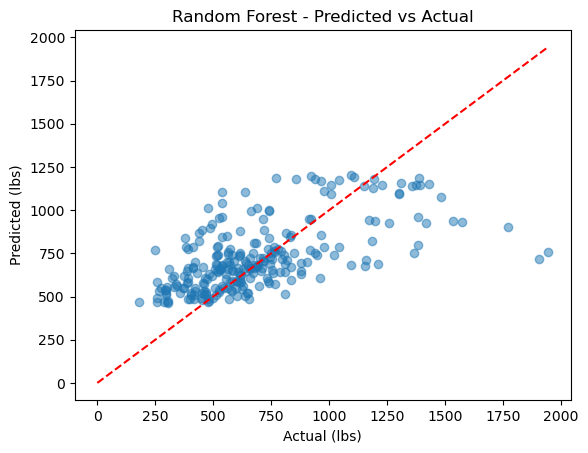

In [125]:
# I used this code to compare the predicted food waste with the real food waste on the test set.
# If the model was perfect, all the points would be on the red line.
y_pred = best_model.predict(X_test)

plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([0, y_test.max()], [0, y_test.max()], color='red', linestyle='--')
plt.xlabel('Actual (lbs)')
plt.ylabel('Predicted (lbs)')
plt.title(best_name + ' - Predicted vs Actual')
plt.show()

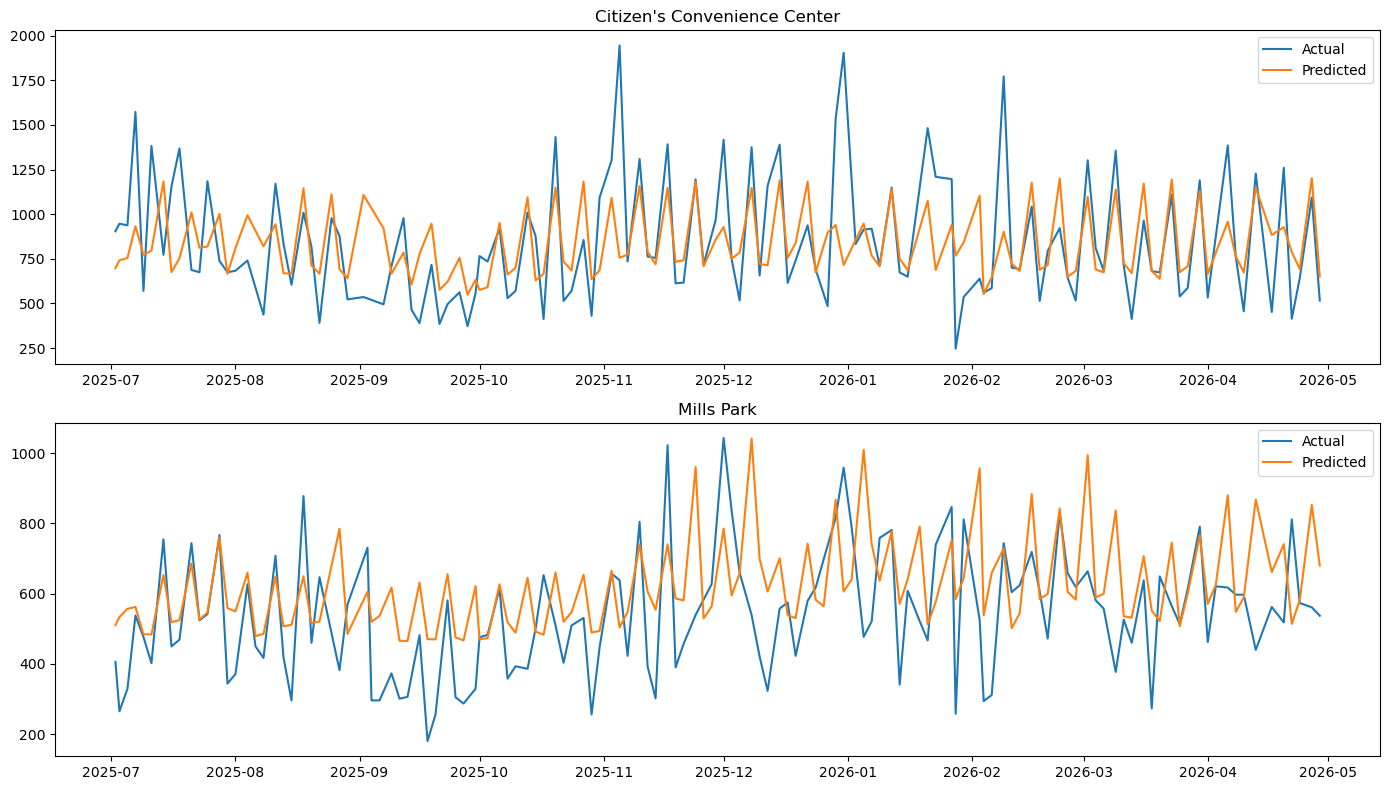

In [126]:
# I used this code to see the real and the predicted food waste over time for each site
test_view = data.loc[X_test.index, ['Collection Date', 'Stop Name', 'Food Waste Collected']].copy()
test_view['predicted'] = y_pred

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, s in zip(axes, test_view['Stop Name'].unique()):
    t = test_view[test_view['Stop Name'] == s]
    ax.plot(t['Collection Date'], t['Food Waste Collected'], label='Actual')
    ax.plot(t['Collection Date'], t['predicted'], label='Predicted')
    ax.set_title(s)
    ax.legend()
plt.tight_layout()
plt.show()